# MX Truncation Research
## Shared scale multiplication and group size sensitivity

This notebook splits the previous combined comparison into **four presentation figures**:

1. Shared scale multiplication — accuracy.
2. Shared scale multiplication — persistent model storage.
3. Group size sensitivity — accuracy.
4. Group size sensitivity — persistent model storage.

The first four rows **of each original figure** are repeated. In the accuracy figures these are dedicated QAT, joint direct QAT, post-training truncation, and truncation-aware training with scale ×1. In the storage figures they are dedicated models, post-training truncation, truncation-aware training with scale ×1, and fixed scale ×32. The original storage figure did not contain a separate joint-direct-QAT case; this revision preserves that definition.

The group-size figures also include the existing **group size 32, scale ×64** run as the control for group sizes 16 and 64. It is the same run as fixed scale ×64 in the shared-scale figures, with a more explicit display label.

All original accuracy measurements, byte counts, run identifiers and provenance records are retained without modification. The embedded figures are ready to view. **Run All** recreates the four figures and exports PNG (300 dpi), SVG, CSV and JSON files to `figures/`. Only Matplotlib and the Python standard library are required. No dataset, checkpoint, GPU, training or internet access is needed.

All figure text is in English. The accuracy plots retain the marked 14–18% and 85–96% axis windows; the storage plots use a continuous zero-based axis.


## 1. Experimental setup

| Setting | Value |
|:--|:--|
| Dataset / model | SVHN / CNN-8 (`svhnq`, `expand=2`) |
| Weight formats | MXFP8 E4M3, MXFP6 E2M3, MXFP4 E2M1 |
| Activations | FP32 (A32) |
| MX group size | 32 unless the row specifies 16 or 64 |
| Shared scale representation | E8M0 |
| Training duration | 100 epochs |
| Optimizer / initial learning rate | Adam / 0.001 |
| Learning-rate milestones / multiplier | 50, 75, 90 / 0.1 |
| Batch size | 128 |
| Weight decay / dropout | 0 / 0.5 |
| Distillation | Joint models only; recursive MXFP8 → MXFP6 → MXFP4 |
| Scale-choice learning rate while learning | 0.001 |
| Training master weights | FP32 |
| Seed / repetitions | 20261009 / one recorded trajectory per configuration |

Dedicated models use one hard-label cross-entropy pass per minibatch. Joint models use three passes, a high-mode hard-label loss, recursive detached soft targets for lower modes, temperature 1, summed gradients without division by three, and one optimizer update. The training objectives and compute budgets therefore differ between dedicated and joint models.

All training accuracy rows preserve the original logged final-checkpoint values at epoch 100. The post-training conversion row is a separate evaluation of the same joint-direct final checkpoint, with zero optimizer steps and no BatchNorm recalibration. The negligible high-mode floating-point difference between training and re-evaluation remains preserved in the underlying data. Best-checkpoint scores are not substituted into this comparison.

Dropout 0.5 is verified in the common architecture source. Full run configurations and hashes are embedded for traceability; preprocessing and dataset-split details are not added to the figure headers.


### What is learned, and what is frozen?

The fixed ×32 and ×64 variants apply a fixed scale relationship during exponent/mantissa truncation. The learned variants select one of these two relationships **per block**. The shared source scale itself remains a dynamic quantity derived from the current weights.

The **until epoch 50, then fixed** variant shares epochs 1–50 with the learned-to-100 trajectory. It branches after epoch 50 and keeps the learned per-block choice/offset values fixed while the rest of training continues to epoch 100. It is not a 50-epoch model or an independently initialized repetition. In the recorded implementation the choice parameter group's learning rate is zero after the branch; its gradients and Adam moments are still computed. The frozen choices remain necessary during inference.

All six new research rows use truncation during training. Group-size 16 and 64 use the fixed ×64 correction. The original grouping flattens input-channel/kernel positions within each output channel and pads row tails; a larger group is therefore not automatically a smaller stored model.


In [1]:
import csv
import io
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator


In [2]:
DATA = json.loads(r'''
{
  "schema": "mx-truncation-research-midterm-v1",
  "dataset": "SVHN",
  "model": "CNN-8",
  "formats": [
    "E4M3",
    "E2M3",
    "E2M1"
  ],
  "training": {
    "epochs": 100,
    "optimizer": "Adam",
    "initial_lr": 0.001,
    "batch_size": 128,
    "lr_milestones": [
      50,
      75,
      90
    ],
    "lr_decay_factor": 0.1,
    "weight_decay": 0.0,
    "dropout_probability": 0.5,
    "activation_bits": 32,
    "group_size": 32,
    "scale_format": "E8M0",
    "distillation": "Recursive knowledge distillation: joint models only",
    "distillation_order": [
      "E4M3",
      "E2M3",
      "E2M1"
    ],
    "seed": 20261009,
    "master_dtype_during_training": "float32",
    "common_run_configuration": {
      "planned_epochs": 100,
      "optimizer": "adam",
      "lr": 0.001,
      "batch_size": 128,
      "scheduler_milestones": [
        50,
        75,
        90
      ],
      "scheduler_gamma": 0.1,
      "weight_decay": 0.0,
      "activation_bits": 32,
      "mx_scale_format": "E8M0",
      "master_dtype": "float32",
      "seed": 20261009,
      "expand": 2
    },
    "group_size_policy": "32 unless specified",
    "scale_choice_learning_rate": 0.001,
    "scale_choice_freeze_epoch": 50,
    "freeze50_total_epochs": 100
  },
  "accuracy": [
    {
      "id": "dedicated",
      "label": "Dedicated QAT \u2014 separate models",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.68346649338734,
          "correct": 24648,
          "n": 26032,
          "training_id": "dedicated_e4m3",
          "run_id": "20261023_132558_081080_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "1c3cd97637c4c88b5f8ccbc9bc81d69046471861fa8fdf65d5245f32a68c7402"
        },
        "E2M3": {
          "accuracy_percent": 94.82559925775698,
          "correct": 24685,
          "n": 26032,
          "training_id": "dedicated_mxfp6",
          "run_id": "20261017_190413_551517_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "e276bea6a3c9a6716a88535800b383fe35de6d77c3d6925a4cadaa0b24e411d1"
        },
        "E2M1": {
          "accuracy_percent": 94.82175783650891,
          "correct": 24684,
          "n": 26032,
          "training_id": "dedicated_mxfp4",
          "run_id": "20261021_182608_167996_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "81d92fff125392a55c7de83a711411d16596f2aff3d26babc8986e176bf02e4a"
        }
      },
      "group_size": 32,
      "section": "Previous exponent-truncation references"
    },
    {
      "id": "joint_direct",
      "label": "Joint QAT \u2014 direct quantization",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.86017208650351,
          "correct": 24694,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        },
        "E2M3": {
          "accuracy_percent": 95.00614627212121,
          "correct": 24732,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        },
        "E2M1": {
          "accuracy_percent": 95.0714505177447,
          "correct": 24749,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        }
      },
      "group_size": 32,
      "section": "Previous exponent-truncation references"
    },
    {
      "id": "post_training_truncation",
      "label": "Joint QAT + post-training exponent & mantissa truncation",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.86017209588199,
          "correct": 24694,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "native_evaluation",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__direct8",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "8",
          "scale_exponent_offset": 0,
          "classes_predicted": 10,
          "dominant_class": 1,
          "dominant_prediction_fraction": 0.1967578365089121,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        },
        "E2M3": {
          "accuracy_percent": 15.938076213890596,
          "correct": 4149,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "posthoc_conversion",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__exponent86",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "32",
          "scale_exponent_offset": 0,
          "classes_predicted": 1,
          "dominant_class": 2,
          "dominant_prediction_fraction": 1.0,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        },
        "E2M1": {
          "accuracy_percent": 15.938076213890596,
          "correct": 4149,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "posthoc_conversion",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__combined864",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "4",
          "scale_exponent_offset": 0,
          "classes_predicted": 1,
          "dominant_class": 2,
          "dominant_prediction_fraction": 1.0,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        }
      },
      "group_size": 32,
      "section": "Previous exponent-truncation references"
    },
    {
      "id": "joint_truncation",
      "label": "Joint truncation-aware training \u2014 scale \u00d71",
      "values": {
        "E4M3": {
          "accuracy_percent": 86.39751075130339,
          "correct": 22491,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        },
        "E2M3": {
          "accuracy_percent": 87.06207744314689,
          "correct": 22664,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        },
        "E2M1": {
          "accuracy_percent": 87.13890596189306,
          "correct": 22684,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        }
      },
      "group_size": 32,
      "section": "Previous exponent-truncation references"
    },
    {
      "id": "fixed_scale32",
      "label": "Fixed scale \u00d732",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.70651505370043,
          "correct": 24654,
          "n": 26032,
          "training_id": "triple_scale32",
          "run_id": "20261024_194510_445043_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "a24b41d9ecb959d1b4b62259fee0f0dcc746cc341ece195d69a99f5a02e21aba"
        },
        "E2M3": {
          "accuracy_percent": 94.85248923931813,
          "correct": 24692,
          "n": 26032,
          "training_id": "triple_scale32",
          "run_id": "20261024_194510_445043_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "a24b41d9ecb959d1b4b62259fee0f0dcc746cc341ece195d69a99f5a02e21aba"
        },
        "E2M1": {
          "accuracy_percent": 94.91395205431506,
          "correct": 24708,
          "n": 26032,
          "training_id": "triple_scale32",
          "run_id": "20261024_194510_445043_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "a24b41d9ecb959d1b4b62259fee0f0dcc746cc341ece195d69a99f5a02e21aba"
        }
      },
      "group_size": 32,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "fresh_training",
        "parent_id": null,
        "shared_epochs": null
      }
    },
    {
      "id": "fixed_scale64",
      "label": "Fixed scale \u00d764",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.9293177580643,
          "correct": 24712,
          "n": 26032,
          "training_id": "triple_scale64",
          "run_id": "20261024_151210_665535_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "0605299354c6eb8dbee48cc318a118f1572e98c133441593c99fc71dcb96217d"
        },
        "E2M3": {
          "accuracy_percent": 94.8985863458766,
          "correct": 24704,
          "n": 26032,
          "training_id": "triple_scale64",
          "run_id": "20261024_151210_665535_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "0605299354c6eb8dbee48cc318a118f1572e98c133441593c99fc71dcb96217d"
        },
        "E2M1": {
          "accuracy_percent": 94.79102641963196,
          "correct": 24676,
          "n": 26032,
          "training_id": "triple_scale64",
          "run_id": "20261024_151210_665535_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "0605299354c6eb8dbee48cc318a118f1572e98c133441593c99fc71dcb96217d"
        }
      },
      "group_size": 32,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "fresh_training",
        "parent_id": null,
        "shared_epochs": null
      }
    },
    {
      "id": "learned100",
      "label": "Learned choice \u00d732/\u00d764 \u2014 until epoch 100",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.9331591840016,
          "correct": 24713,
          "n": 26032,
          "training_id": "triple_learned100",
          "run_id": "20261025_150724_515132_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "44bc5709a0c994cb5da567693b334432cb76828d5ece043bd049c381a91fd57b"
        },
        "E2M3": {
          "accuracy_percent": 94.1763982696627,
          "correct": 24516,
          "n": 26032,
          "training_id": "triple_learned100",
          "run_id": "20261025_150724_515132_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "44bc5709a0c994cb5da567693b334432cb76828d5ece043bd049c381a91fd57b"
        },
        "E2M1": {
          "accuracy_percent": 93.94975414405077,
          "correct": 24457,
          "n": 26032,
          "training_id": "triple_learned100",
          "run_id": "20261025_150724_515132_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "44bc5709a0c994cb5da567693b334432cb76828d5ece043bd049c381a91fd57b"
        }
      },
      "group_size": 32,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "fresh_training",
        "parent_id": null,
        "shared_epochs": null
      }
    },
    {
      "id": "freeze50",
      "label": "Learned choice \u00d732/\u00d764 \u2014 until epoch 50, then fixed",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.77566072057198,
          "correct": 24672,
          "n": 26032,
          "training_id": "triple_freeze50",
          "run_id": "20261025_183915_084406_freeze100_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "f2c2bb1b4c26336ec9301fa117f3b3bd27e4668dd90c8a47dd3f8f4fada718bb"
        },
        "E2M3": {
          "accuracy_percent": 94.71419790088581,
          "correct": 24656,
          "n": 26032,
          "training_id": "triple_freeze50",
          "run_id": "20261025_183915_084406_freeze100_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "f2c2bb1b4c26336ec9301fa117f3b3bd27e4668dd90c8a47dd3f8f4fada718bb"
        },
        "E2M1": {
          "accuracy_percent": 94.52596802995772,
          "correct": 24607,
          "n": 26032,
          "training_id": "triple_freeze50",
          "run_id": "20261025_183915_084406_freeze100_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "f2c2bb1b4c26336ec9301fa117f3b3bd27e4668dd90c8a47dd3f8f4fada718bb"
        }
      },
      "group_size": 32,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "continuation_branch",
        "parent_id": "triple_learned100",
        "shared_epochs": [
          1,
          50
        ],
        "freeze_after_epoch": 50,
        "frozen_epoch_range": [
          51,
          100
        ],
        "continuation_stages": [
          [
            51,
            55
          ],
          [
            56,
            100
          ]
        ],
        "global_best_inherited": true,
        "selected_source_stage": "shared_before_freeze",
        "new_optimizer_steps_after_branchpoint": 28650,
        "new_training_passes_after_branchpoint": 85950,
        "offset_values_fixed": true,
        "source_scale_dynamic": true,
        "theta_gradients_computed": true,
        "theta_adam_moments_updated": true
      }
    },
    {
      "id": "group16",
      "label": "Group size 16 \u2014 scale \u00d764",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.79102642901044,
          "correct": 24676,
          "n": 26032,
          "training_id": "triple_group16",
          "run_id": "20261026_190508_857016_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "06c2dcf70d976f911c2b4cb0793158ff735aff246df611d766f8b14b46231fa4"
        },
        "E2M3": {
          "accuracy_percent": 94.54517515964426,
          "correct": 24612,
          "n": 26032,
          "training_id": "triple_group16",
          "run_id": "20261026_190508_857016_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "06c2dcf70d976f911c2b4cb0793158ff735aff246df611d766f8b14b46231fa4"
        },
        "E2M1": {
          "accuracy_percent": 94.57206514120541,
          "correct": 24619,
          "n": 26032,
          "training_id": "triple_group16",
          "run_id": "20261026_190508_857016_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "06c2dcf70d976f911c2b4cb0793158ff735aff246df611d766f8b14b46231fa4"
        }
      },
      "group_size": 16,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "fresh_training",
        "parent_id": null,
        "shared_epochs": null
      }
    },
    {
      "id": "group64",
      "label": "Group size 64 \u2014 scale \u00d764",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.69114934526196,
          "correct": 24650,
          "n": 26032,
          "training_id": "triple_group64",
          "run_id": "20261027_172434_760515_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "c2fd1551b4ce067d35a8f16f94c61ecddd707114f1219059301582b673897b45"
        },
        "E2M3": {
          "accuracy_percent": 94.54517515964426,
          "correct": 24612,
          "n": 26032,
          "training_id": "triple_group64",
          "run_id": "20261027_172434_760515_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "c2fd1551b4ce067d35a8f16f94c61ecddd707114f1219059301582b673897b45"
        },
        "E2M1": {
          "accuracy_percent": 94.51060233089773,
          "correct": 24603,
          "n": 26032,
          "training_id": "triple_group64",
          "run_id": "20261027_172434_760515_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "c2fd1551b4ce067d35a8f16f94c61ecddd707114f1219059301582b673897b45"
        }
      },
      "group_size": 64,
      "section": "Scale and group-size research",
      "lineage": {
        "kind": "fresh_training",
        "parent_id": null,
        "shared_epochs": null
      }
    }
  ],
  "storage": [
    {
      "id": "triple_dedicated_separate",
      "label": "Dedicated models",
      "group_size": 32,
      "representation": "Three packed models: MXFP8 + MXFP6 + MXFP4",
      "code_bytes": 293760,
      "scale_bytes": 12240,
      "choice_bytes": 0,
      "retained_state_bytes": 57744,
      "total_bytes": 363744,
      "auxiliary_copies": 3,
      "implementation": "existing_separate_exports",
      "accuracy_method_id": "dedicated",
      "delta_vs_naive_bytes": 209856
    },
    {
      "id": "triple_direct_posthoc_source",
      "label": "Joint QAT + post-training truncation",
      "group_size": 32,
      "representation": "One MXFP8 source; lower modes by exponent and mantissa truncation, scale unchanged",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "joint_direct_MXFP8_source_with_post_training_exponent_and_mantissa_truncation",
      "accuracy_method_id": "post_training_truncation",
      "delta_vs_naive_bytes": 0
    },
    {
      "id": "triple_naive_source",
      "label": "Joint truncation-aware training \u2014 scale \u00d71",
      "group_size": 32,
      "representation": "One MXFP8 source; lower modes by exponent and mantissa truncation, scale unchanged",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "joint_truncation",
      "delta_vs_naive_bytes": 0
    },
    {
      "id": "triple_scale32_source",
      "label": "Fixed scale \u00d732",
      "group_size": 32,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "fixed_scale32",
      "delta_vs_naive_bytes": 0
    },
    {
      "id": "triple_scale64_source",
      "label": "Fixed scale \u00d764",
      "group_size": 32,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "fixed_scale64",
      "delta_vs_naive_bytes": 0
    },
    {
      "id": "triple_learned100_source",
      "label": "Learned choice \u00d732/\u00d764 \u2014 until epoch 100",
      "group_size": 32,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 510,
      "retained_state_bytes": 19248,
      "total_bytes": 154398,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "learned100",
      "delta_vs_naive_bytes": 510
    },
    {
      "id": "triple_freeze50_source",
      "label": "Learned choice \u00d732/\u00d764 \u2014 until epoch 50, then fixed",
      "group_size": 32,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "choice_bytes": 510,
      "retained_state_bytes": 19248,
      "total_bytes": 154398,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "freeze50",
      "delta_vs_naive_bytes": 510
    },
    {
      "id": "triple_group16_source",
      "label": "Group size 16 \u2014 scale \u00d764",
      "group_size": 16,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 129536,
      "scale_bytes": 8096,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 156880,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "group16",
      "delta_vs_naive_bytes": 2992
    },
    {
      "id": "triple_group64_source",
      "label": "Group size 64 \u2014 scale \u00d764",
      "group_size": 64,
      "representation": "One MXFP8 source; lower formats derived using the trained truncation route",
      "code_bytes": 138240,
      "scale_bytes": 2160,
      "choice_bytes": 0,
      "retained_state_bytes": 19248,
      "total_bytes": 159648,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "group64",
      "delta_vs_naive_bytes": 5760
    }
  ],
  "accuracy_axis_windows": [
    [
      14.0,
      18.0
    ],
    [
      85.0,
      96.0
    ]
  ],
  "storage_accounting": {
    "group_layouts": {
      "16": {
        "id": "mx_e4m3_b16",
        "group_size": 16,
        "n_weights": 129472,
        "blocks": 8096,
        "stored_slots": 129536,
        "padding_slots": 64,
        "code_bytes": 129536,
        "scale_bytes": 8096,
        "aux_bytes": 19248,
        "total_model_bytes": 156880
      },
      "32": {
        "id": "mx_e4m3_b32",
        "group_size": 32,
        "n_weights": 129472,
        "blocks": 4080,
        "stored_slots": 130560,
        "padding_slots": 1088,
        "code_bytes": 130560,
        "scale_bytes": 4080,
        "aux_bytes": 19248,
        "total_model_bytes": 153888
      },
      "64": {
        "id": "mx_e4m3_b64",
        "group_size": 64,
        "n_weights": 129472,
        "blocks": 2160,
        "stored_slots": 138240,
        "padding_slots": 8768,
        "code_bytes": 138240,
        "scale_bytes": 2160,
        "aux_bytes": 19248,
        "total_model_bytes": 159648
      }
    },
    "target_weight_count": 129472,
    "fp32_first_last_bytes_per_model": 8808,
    "batchnorm_bytes_per_model_all_five_banks": 10440,
    "retained_state_bytes_per_model": 19248,
    "learned_choice_bits_per_group": 1,
    "learned_choice_group_count": 4080,
    "learned_choice_packed_bytes": 510,
    "reference_source_bytes": 153888,
    "scope": "Logical persistent model payload supporting all three modes; includes code padding, E8M0 scales, packed scale-choice bits where used, FP32 first/last layers, and all five existing BatchNorm banks per model copy. Excludes activations, temporary runtime buffers, optimizer state, gradients and file-container overhead."
  },
  "eight_by_eight": {
    "main_figure_included": false,
    "verified_epoch100_record_in_source": false,
    "status": "A five-epoch pilot was discussed previously; no verified 100-epoch result is present in the source dataset used for these figures.",
    "not_equivalent_to": "The one-dimensional group-size-64 experiment"
  },
  "provenance": {
    "source_notebook": "MX_onderzoeksoverzicht_meeting_20261029.ipynb",
    "source_notebook_library_id": "libfile_6fcbc29932c88191b47bf7be6a45d2f1",
    "decoded_source_sha256": "145471897ecfb37c5741e076c213d674e1e1920a29c7fb1077e39a94ccdefd83",
    "reference_notebook": "MX_Exponent_Truncation_SVHN_CNN8_Midterm.ipynb",
    "reference_notebook_sha256": "6f5ea9f6283642436eeef21c7aa19de5fc713ed5eeaee06c1caa49d6c2dcc706",
    "training_sources": {
      "dedicated_e4m3": {
        "run_id": "20261023_132558_081080_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-121902).zip",
          "zip_sha256": "db59f4677a72bbbe5d5abe5fdb91afb53d6330904218dfd5620a8b7285c6407d",
          "metrics_path": "sources/training/dedicated_e4m3/epoch_metrics.csv",
          "metrics_sha256": "048305dbf277809c7a68d01cb3588f0063933bbd92276fc31129e2dbb7a976cd",
          "report_path": "sources/training/dedicated_e4m3/run_report.json",
          "report_sha256": "12118850ee093fa17ed91aaf1d31a985d73960bd878186daaf4db27c980b2d89",
          "selection_path": "sources/training/dedicated_e4m3/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_e4m3/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_e4m3/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "dedicated_mxfp6": {
        "run_id": "20261017_190413_551517_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(9).zip",
          "zip_sha256": "a9a3cf057abc0957778259e0e960538921d89f74e4f953868ca569655f1c1f9d",
          "metrics_path": "sources/training/dedicated_mxfp6/epoch_metrics.csv",
          "metrics_sha256": "fc96fcb071fbb4fe480d88995310dadeda8eb619a3f428bd0b25a2bf870f33ea",
          "report_path": "sources/training/dedicated_mxfp6/run_report.json",
          "report_sha256": "e9cbbc16f4168c3ebb6de0f1c7bf1162b913c81de1934a969ed87f22874ad872",
          "selection_path": "sources/training/dedicated_mxfp6/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp6/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp6/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "dedicated_mxfp4": {
        "run_id": "20261021_182608_167996_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(20261021-171049).zip",
          "zip_sha256": "951f865bc08883bbe88cbe8d14b76a2f612a454b6cef058e15f3a9784b13dc86",
          "metrics_path": "sources/training/dedicated_mxfp4/epoch_metrics.csv",
          "metrics_sha256": "5e526a4c2633a97e37087802e3212b5a7ecb1d2e0e4612b0154da91172abae00",
          "report_path": "sources/training/dedicated_mxfp4/run_report.json",
          "report_sha256": "9d192214376689a0f39547ddad3162132d997312f3afed74e880acf0677c085d",
          "selection_path": "sources/training/dedicated_mxfp4/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp4/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp4/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_direct": {
        "run_id": "20261023_151331_732669_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-150530).zip",
          "zip_sha256": "68b55b2432bdc6802094e8968ad5d97252b8166ebbca4d1651fc438c6c66e259",
          "metrics_path": "sources/training/triple_direct/epoch_metrics.csv",
          "metrics_sha256": "52df99915d90f3626399db078f610ac4a2ada7658052eed37ed76a7cd0a006c8",
          "report_path": "sources/training/triple_direct/run_report.json",
          "report_sha256": "0016d288cbc372e1d1341435357a258f92a93bef3b13d2f3141dca030d2f776c",
          "selection_path": "sources/training/triple_direct/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_direct/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_direct/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": false,
          "mantissa_truncation": false,
          "exponent_truncation": false,
          "shared_scale_compensation": false,
          "learned_shared_scale": false,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_naive": {
        "run_id": "20261023_184058_211397_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-181200).zip",
          "zip_sha256": "4d31fe092f620ceb044b576d279580b49f8ff4473e1ae37957a04169f37012c7",
          "metrics_path": "sources/training/triple_naive/epoch_metrics.csv",
          "metrics_sha256": "a9ec9ac706b75af6c7144da6ded18286cf676cdee724444892974c627d2bd337",
          "report_path": "sources/training/triple_naive/run_report.json",
          "report_sha256": "2d748a0bf643131d2f99a004cbb82c325133be115823e73d3ec918a4d827d5e6",
          "selection_path": "sources/training/triple_naive/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_naive/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_naive/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": false,
          "learned_shared_scale": false,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_scale32": {
        "run_id": "20261024_194510_445043_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261025-124719).zip",
          "zip_sha256": "f4ec1fa26336e2ad6552f0ae39a5a9c5e1f14dcbcc255818edb8c9bf7ba56e00",
          "metrics_path": "sources/training/triple_scale32/epoch_metrics.csv",
          "metrics_sha256": "2269bb98b6e2838ae2bddfb4a674fc2c2b0f5b535bfbea744d2d23ef833f89ac",
          "report_path": "sources/training/triple_scale32/run_report.json",
          "report_sha256": "be771afb34ad1043a07a77e0ceee50f591e3155578fc8a7a04960c60f3dda6a8",
          "selection_path": "sources/training/triple_scale32/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_scale32/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_scale32/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": false,
          "scale_factor": 32,
          "scale_exponent_offset": 5,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_scale64": {
        "run_id": "20261024_151210_665535_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261024-145841).zip",
          "zip_sha256": "811b18d3878d7699a01fb7e9a449e9591bcbe07d56aee56bb76bd36a32d47887",
          "metrics_path": "sources/training/triple_scale64/epoch_metrics.csv",
          "metrics_sha256": "cb6c9ddcff6c263bf24c3cde3b02bab8ead694ae21e278b58d1632bf67ce60ab",
          "report_path": "sources/training/triple_scale64/run_report.json",
          "report_sha256": "f53511694e0762f55cf5b3fb8b85e9e0a2738b91a415b825418b10cb5398db0c",
          "selection_path": "sources/training/triple_scale64/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_scale64/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_scale64/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": false,
          "scale_factor": 64,
          "scale_exponent_offset": 6,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_learned100": {
        "run_id": "20261025_150724_515132_joint_run",
        "source": {
          "bundle_name": "lineage.json",
          "zip_sha256": "6c7725d81e981991f4ecac067687e532082f45dc9653e9f510216c9838280afb",
          "metrics_path": "sources/training/triple_learned100/epoch_metrics.csv",
          "metrics_sha256": "21bc82c1506d153fbadba7b0fb7372eaa1da7af7bd1076cee55045307ae11bca",
          "report_path": "sources/training/triple_learned100/run_report.json",
          "report_sha256": "b8aa053be06c0c58073666446fddac3993c35dc13398f9efe131c33e6720f438",
          "selection_path": "sources/training/triple_learned100/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_learned100/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_learned100/epoch_times.csv",
          "scale_metrics_path": "sources/training/triple_learned100/scale_epoch_metrics.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 137034,
          "base_parameters": 132954,
          "learned_scale_parameters": 4080,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "scale_lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": true,
          "scale_factor_choices": [
            32,
            64
          ],
          "scale_exponent_offset_choices": [
            5,
            6
          ],
          "scale_proxy_bounds": [
            5.0,
            6.0
          ],
          "scale_threshold": 5.5,
          "source_scale_learned": false,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_freeze50": {
        "run_id": "20261025_183915_084406_freeze100_run",
        "source": {
          "bundle_name": "lineage.json",
          "zip_sha256": "43355332b6be546f3a73a71d075f73e1668e6c5493644f83239d97c3512d6b4b",
          "metrics_path": "sources/training/triple_freeze50/epoch_metrics.csv",
          "metrics_sha256": "6b19f3ad14ddc825bd8111a80b8949114f7b0600e2ad9849766f6c8ae349a2f7",
          "report_path": "sources/training/triple_freeze50/run_report.json",
          "report_sha256": "95eae353a7cbd6fd60dba8244df65a40d1c82b2e6f2fef2f1646ed4b1e6c5dd4",
          "selection_path": "sources/training/triple_freeze50/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_freeze50/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_freeze50/epoch_times.csv",
          "scale_metrics_path": "sources/training/triple_freeze50/scale_epoch_metrics.csv",
          "metrics_epoch_range": [
            51,
            100
          ],
          "inherited_metrics_path": "sources/training/triple_learned100/epoch_metrics.csv",
          "inherited_metrics_epoch_range": [
            1,
            50
          ],
          "inherited_scale_metrics_path": "sources/training/triple_learned100/scale_epoch_metrics.csv"
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 137034,
          "base_parameters": 132954,
          "learned_scale_parameters": 4080,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "scale_lr": 0.0,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": true,
          "scale_factor_choices": [
            32,
            64
          ],
          "scale_exponent_offset_choices": [
            5,
            6
          ],
          "scale_proxy_bounds": [
            5.0,
            6.0
          ],
          "scale_threshold": 5.5,
          "source_scale_learned": false,
          "offset_updates_enabled": false,
          "source_scale_dynamic": true,
          "freeze_anchor_epoch": 50,
          "theta_gradients_computed": true,
          "theta_adam_moments_updated": true,
          "freeze_method": "theta Adam-group lr=0; requires_grad remains true; scheduler scale group lr/base_lrs/last_lr zero",
          "selection_policy": "first strict maximum E4M3 official-test top1 within51-100; additional global1-100 selection explicitly labelled by stage",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "continuation_branch",
          "parent_id": "triple_learned100",
          "shared_epochs": [
            1,
            50
          ],
          "freeze_after_epoch": 50,
          "frozen_epoch_range": [
            51,
            100
          ],
          "continuation_stages": [
            [
              51,
              55
            ],
            [
              56,
              100
            ]
          ],
          "global_best_inherited": true,
          "selected_source_stage": "shared_before_freeze",
          "new_optimizer_steps_after_branchpoint": 28650,
          "new_training_passes_after_branchpoint": 85950,
          "offset_values_fixed": true,
          "source_scale_dynamic": true,
          "theta_gradients_computed": true,
          "theta_adam_moments_updated": true
        }
      },
      "triple_group16": {
        "run_id": "20261026_190508_857016_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261026-195319).zip",
          "zip_sha256": "c8d3f0ff1d4f74eccda551a0c2c8cb3710cdcac8dddcc9c7fd22288fc4587271",
          "metrics_path": "sources/training/triple_group16/epoch_metrics.csv",
          "metrics_sha256": "5c9669b12473e3f7d9cb07b25a228805248ffa7fb2b1372e50f825578bed2530",
          "report_path": "sources/training/triple_group16/run_report.json",
          "report_sha256": "91a2b18d569d2097b72181cf278d7a087e3bd52afd9b753d60bcdaed09843a48",
          "selection_path": "sources/training/triple_group16/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_group16/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_group16/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 16,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": false,
          "scale_factor": 64,
          "scale_exponent_offset": 6,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      },
      "triple_group64": {
        "run_id": "20261027_172434_760515_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261027-180420).zip",
          "zip_sha256": "ead1f28e75810021579bd303f6a695c17b76bd8389b3881538b9be6a08b198f0",
          "metrics_path": "sources/training/triple_group64/epoch_metrics.csv",
          "metrics_sha256": "3d1bbdca0943aba4ac9e22950fe7f44687da0480b656171b14e1c5c3647b4f61",
          "report_path": "sources/training/triple_group64/run_report.json",
          "report_sha256": "dc4e7d8c26c30d955238eddb768916604efcfd16e8ac82cd2632f0bcac15c4ae",
          "selection_path": "sources/training/triple_group64/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_group64/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_group64/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 64,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": true,
          "learned_shared_scale": false,
          "scale_factor": 64,
          "scale_exponent_offset": 6,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        },
        "lineage": {
          "kind": "fresh_training",
          "parent_id": null,
          "shared_epochs": null
        }
      }
    },
    "dropout_evidence": {
      "source": "Any-Precision-DNNs-master.zip / models/svhn_quan.py",
      "source_sha256": "c891da23c7d2934cd65e3c596c3e47b47de8987385bc8d06eab22de7d2d02e74",
      "setting": "nn.Dropout(0.5) in the common CNN-8 architecture",
      "verification_scope": "Architecture setting; no new inspection of binary models or per-run wrapper code."
    },
    "posthoc_case_ids": {
      "E4M3": "triple_initial__triple_direct__last_epoch__direct8",
      "E2M3": "triple_initial__triple_direct__last_epoch__exponent86",
      "E2M1": "triple_initial__triple_direct__last_epoch__combined864"
    },
    "joint_qat_single_source": {
      "training_id": "triple_direct",
      "export_file": "mx_direct_MXFP8_E4M3_last.pt",
      "export_sha256": "d692c4b293ea924281ffd1698020bd8cff2a486f663ee62babf24c5f6afbec9d",
      "source_report_sha256": "0016d288cbc372e1d1341435357a258f92a93bef3b13d2f3141dca030d2f776c",
      "logical_source_bytes": 153888,
      "accuracy_figure_row": "post_training_truncation"
    },
    "storage_calculation_method": "Read-only recomputation from tensor metadata; validated against actual full100 group reports and all full100 export layer CSVs.",
    "reference_rows_preserved": true,
    "original_logged_training_metrics_preserved": true,
    "new_training_or_model_evaluation": false,
    "checkpoints_or_binary_exports_loaded": false
  }
}
''')


In [3]:
ACCURACY_BY_ID = {row['id']: row for row in DATA['accuracy']}
STORAGE_BY_METHOD = {row['accuracy_method_id']: row for row in DATA['storage']}

# Keep the first four rows of each ORIGINAL figure in their original order.
ACCURACY_REFERENCES = [row['id'] for row in DATA['accuracy'][:4]]
STORAGE_REFERENCES = [row['accuracy_method_id'] for row in DATA['storage'][:4]]
SCALE_VARIANTS = ['fixed_scale32', 'fixed_scale64', 'learned100', 'freeze50']
GROUP_VARIANTS = ['group16', 'fixed_scale64', 'group64']

def ordered_unique(values):
    return list(dict.fromkeys(values))

FIGURE_SELECTIONS = {
    'shared_scale_accuracy': ordered_unique(ACCURACY_REFERENCES + SCALE_VARIANTS),
    'shared_scale_storage': ordered_unique(STORAGE_REFERENCES + SCALE_VARIANTS),
    'group_size_accuracy': ordered_unique(ACCURACY_REFERENCES + GROUP_VARIANTS),
    'group_size_storage': ordered_unique(STORAGE_REFERENCES + GROUP_VARIANTS),
}

REVISION = {
    'description': 'Split the combined research figures by shared scale and group size',
    'source_notebook': 'MX_Truncation_Research_SVHN_CNN8_Midterm.ipynb',
    'data_policy': 'Original embedded DATA copied without changing measurements or accounting',
    'reference_policy': 'First four rows of each original figure',
    'group32_control_method_id': 'fixed_scale64',
}


In [4]:
FIGURE_SIZE = (17.5, 10.0)
EXPORT_DIR = Path('figures')
EXPORT_DPI = 300
ACCURACY_WINDOWS = [(14.0, 18.0), (85.0, 96.0)]
LABEL_DECIMALS = 3

NAVY = '#19384B'
MUTED = '#526C7E'
GRID = '#DFE6EC'
SPINE = '#BCCAD4'
ROW_BAND = '#F3F5F7'
MODE_COLORS = {'E4M3': '#3D6789', 'E2M3': '#4C8D80', 'E2M1': '#B77E32'}
STORAGE_FIELDS = ['code_bytes', 'scale_bytes', 'choice_bytes', 'retained_state_bytes']
STORAGE_COMPONENTS = ['Packed weight codes', 'MX block scales', 'Scale-choice bits', 'FP32 layers + BatchNorm']
STORAGE_COLORS = ['#25658A', '#73B5AC', '#D49A43', '#9BAEBE']

mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 14,
    'text.color': NAVY, 'axes.labelcolor': NAVY,
    'xtick.color': NAVY, 'ytick.color': NAVY,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'svg.fonttype': 'none',
})

ACCURACY_LABELS = {
    'dedicated': 'Dedicated QAT — separate models',
    'joint_direct': 'Joint QAT — direct quantization',
    'post_training_truncation': 'Joint QAT + post-training\nexponent & mantissa truncation',
    'joint_truncation': 'Joint truncation-aware training\n— scale ×1',
    'fixed_scale32': 'Fixed scale ×32',
    'fixed_scale64': 'Fixed scale ×64',
    'learned100': 'Learned choice ×32/×64\n— until epoch 100',
    'freeze50': 'Learned choice ×32/×64\n— until epoch 50, then fixed',
    'group16': 'Group size 16 — scale ×64',
    'group64': 'Group size 64 — scale ×64',
}
STORAGE_LABELS = {
    'dedicated': 'Dedicated models\n— three MX models',
    'post_training_truncation': 'Joint QAT + post-training truncation\n— one MXFP8 source',
    'joint_truncation': 'Joint truncation-aware training — scale ×1\n— one MXFP8 source',
    'fixed_scale32': 'Fixed scale ×32\n— one MXFP8 source',
    'fixed_scale64': 'Fixed scale ×64\n— one MXFP8 source',
    'learned100': 'Learned choice ×32/×64 until epoch 100\n— one MXFP8 source',
    'freeze50': 'Learned choice until epoch 50, then fixed\n— one MXFP8 source',
    'group16': 'Group size 16 — scale ×64\n— one MXFP8 source',
    'group64': 'Group size 64 — scale ×64\n— one MXFP8 source',
}

def display_label(method_id, storage=False, group_study=False):
    if group_study and method_id == 'fixed_scale64':
        return ('Group size 32 — scale ×64\n— one MXFP8 source' if storage
                else 'Group size 32 — scale ×64\n(reference)')
    return (STORAGE_LABELS if storage else ACCURACY_LABELS)[method_id]

def add_heading(fig, title, training=True, group_study=False):
    fig.text(0.040, 0.963, title, fontsize=28, weight='bold', va='top')
    fig.text(0.040, 0.907, 'Dataset: SVHN  |  Model: CNN-8', fontsize=18, va='top')
    group_policy = '32 unless specified' if group_study else '32'
    if training:
        t = DATA['training']
        milestones = ', '.join(map(str, t['lr_milestones']))
        lines = [
            f"Epochs: {t['epochs']}  |  {t['optimizer']}  |  Initial LR: {t['initial_lr']:g}  |  Batch size: {t['batch_size']}",
            f"LR milestones: {milestones}  |  LR decay factor: {t['lr_decay_factor']:g}  |  Weight decay: {t['weight_decay']:g}  |  Dropout: {t['dropout_probability']:g}",
            f"Activations: FP32  |  MX group size: {group_policy}  |  {t['distillation']}",
            'Accuracy windows: 14–18% and 85–96% (broken axis)',
        ]
        for y, line in zip([0.852, 0.814, 0.776, 0.738], lines):
            fig.text(0.040, y, line, fontsize=13.2, color=MUTED, va='top')
    else:
        fig.text(0.040, 0.850,
                 'MXFP8 · E4M3 / A32  |  MXFP6 · E2M3 / A32  |  MXFP4 · E2M1 / A32',
                 fontsize=16, color=MUTED, va='top')
        fig.text(0.040, 0.804,
                 f'MX group size: {group_policy}  |  Persistent model storage for all three modes',
                 fontsize=14, color=MUTED, va='top')

def style_axes(ax):
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(SPINE)
        ax.spines[side].set_linewidth(0.9)
    ax.tick_params(length=3, width=0.8, labelsize=12)

def add_break_marks(ax, edge):
    # Express the diagonal marks in points so their size is independent of DPI.
    position = ax.get_position()
    dx = 2.7 / (ax.figure.get_figwidth() * 72 * position.width)
    dy = 2.7 / (ax.figure.get_figheight() * 72 * position.height)
    x = 1.0 if edge == 'right' else 0.0
    for y in (0.0, 1.0):
        ax.plot([x-dx, x+dx], [y-dy, y+dy], transform=ax.transAxes,
                color=NAVY, linewidth=1.2, clip_on=False, zorder=5)

def make_accuracy_figure(method_ids, title, group_study=False):
    rows = [ACCURACY_BY_ID[mid] for mid in method_ids]
    labels = [display_label(mid, group_study=group_study) for mid in method_ids]
    fig = plt.figure(figsize=FIGURE_SIZE)
    add_heading(fig, title, training=True, group_study=group_study)
    n = len(rows)
    panel_width, low_width = 0.195, 0.045
    high_width = low_width * (ACCURACY_WINDOWS[1][1]-ACCURACY_WINDOWS[1][0]) / (ACCURACY_WINDOWS[0][1]-ACCURACY_WINDOWS[0][0])
    break_gap = panel_width-low_width-high_width
    assert break_gap > 0
    plotted = 0
    panels = [('E4M3', 'MXFP8 · E4M3 / A32', 0.3350),
              ('E2M3', 'MXFP6 · E2M3 / A32', 0.5525),
              ('E2M1', 'MXFP4 · E2M1 / A32', 0.7700)]
    for column, (mode, panel_title, left) in enumerate(panels):
        fig.text(left+panel_width/2, 0.677, panel_title,
                 fontsize=16.3, weight='bold', ha='center', va='bottom')
        fig.text(left+panel_width/2, 0.037, 'Test accuracy [%]',
                 fontsize=14, ha='center', va='bottom')
        for segment, ((lo, hi), start, width) in enumerate(zip(
                ACCURACY_WINDOWS, [left, left+low_width+break_gap], [low_width, high_width])):
            ax = fig.add_axes([start, 0.092, width, 0.550])
            style_axes(ax)
            if segment == 1:
                ax.spines['left'].set_visible(False)
            for y in range(0, n, 2):
                ax.axhspan(y-0.46, y+0.46, color=ROW_BAND, zorder=0)
            for y in ([3.5] if group_study else [3.5, 5.5]):
                ax.axhline(y, color=SPINE, linewidth=1.0, zorder=1)
            ax.xaxis.grid(True, color=GRID, linewidth=0.9)
            for y, row in enumerate(rows):
                value = row['values'][mode]['accuracy_percent']
                if not lo <= value <= hi:
                    continue
                plotted += 1
                ax.scatter([value], [y], s=108, color=MODE_COLORS[mode],
                           edgecolors='white', linewidths=0.8, zorder=3)
                if segment == 0:
                    offset, align, vertical, font = (0, 10), 'center', 'bottom', 12.2
                else:
                    high = value >= 91.0
                    offset, align, vertical, font = ((-9 if high else 9), 0), ('right' if high else 'left'), 'center', 13.1
                ax.annotate(f'{value:.{LABEL_DECIMALS}f}%', (value, y), xytext=offset,
                            textcoords='offset points', ha=align, va=vertical,
                            fontsize=font, color=MODE_COLORS[mode])
            ax.set_xlim(lo, hi)
            ax.set_ylim(n-0.5, -0.5)
            ax.xaxis.set_major_locator(FixedLocator([14, 16, 18] if segment == 0 else [86, 88, 90, 92, 94, 96]))
            ax.set_yticks(list(range(n)), labels if column == 0 and segment == 0 else ['']*n)
            ax.tick_params(axis='y', length=0, labelsize=14.0, pad=13)
            ax.tick_params(axis='x', labelsize=11)
            add_break_marks(ax, 'right' if segment == 0 else 'left')
    assert plotted == 3*len(method_ids)
    return fig

def make_storage_figure(method_ids, title, group_study=False):
    rows = [STORAGE_BY_METHOD[mid] for mid in method_ids]
    fig = plt.figure(figsize=FIGURE_SIZE)
    add_heading(fig, title, training=False, group_study=group_study)
    ax = fig.add_axes([0.335, 0.105, 0.620, 0.565])
    style_axes(ax)
    ax.spines['left'].set_visible(False)
    ax.xaxis.grid(True, color=GRID, linewidth=0.9)
    ax.axhline(3.5, color=SPINE, linewidth=1.0, zorder=0)
    for y, row in enumerate(rows):
        left = 0.0
        for field, color in zip(STORAGE_FIELDS, STORAGE_COLORS):
            width = row[field]/1024
            if width:
                ax.barh(y, width, left=left, height=0.48, color=color, zorder=3)
            left += width
        ax.annotate(f"{row['total_bytes']/1024:.2f} KiB", (left, y), xytext=(10, 0),
                    textcoords='offset points', ha='left', va='center', fontsize=15, weight='bold')
    ax.set_yticks(list(range(len(rows))),
                 [display_label(mid, storage=True, group_study=group_study) for mid in method_ids])
    ax.tick_params(axis='y', length=0, labelsize=13.5, pad=13)
    ax.set_ylim(len(rows)-0.45, -0.55)
    ax.set_xlim(0, 410)
    ax.set_xticks([0, 100, 200, 300, 400])
    ax.set_xlabel('Persistent model storage [KiB]', fontsize=15, labelpad=13)
    fig.legend(handles=[Patch(facecolor=color, label=label)
                        for color, label in zip(STORAGE_COLORS, STORAGE_COMPONENTS)],
               loc='upper left', bbox_to_anchor=(0.335, 0.744), ncol=4,
               frameon=False, fontsize=12.2, handlelength=1.0, columnspacing=1.15)
    return fig


In [5]:
# Validate the measurements and accounting that this plotting notebook depends on.
for row in DATA['accuracy']:
    for mode in DATA['formats']:
        value = row['values'][mode]
        assert value['epoch'] == 100 and value['n'] == 26032
        assert abs(100 * value['correct'] / value['n'] - value['accuracy_percent']) < 1e-6
        assert sum(lo <= value['accuracy_percent'] <= hi for lo, hi in ACCURACY_WINDOWS) == 1
for value in ACCURACY_BY_ID['post_training_truncation']['values'].values():
    assert value['optimizer_steps'] == 0 and not value['batchnorm_recalibrated']
for row in DATA['storage']:
    assert sum(row[key] for key in STORAGE_FIELDS) == row['total_bytes']
for layout in DATA['storage_accounting']['group_layouts'].values():
    assert layout['stored_slots'] == layout['blocks'] * layout['group_size']
    assert layout['stored_slots'] - layout['n_weights'] == layout['padding_slots']
    assert layout['code_bytes'] + layout['scale_bytes'] + layout['aux_bytes'] == layout['total_model_bytes']
for name, methods in FIGURE_SELECTIONS.items():
    refs = ACCURACY_REFERENCES if name.endswith('accuracy') else STORAGE_REFERENCES
    assert methods[:4] == refs and len(methods) == len(set(methods))
assert [len(v) for v in FIGURE_SELECTIONS.values()] == [8, 7, 7, 7]
assert {row['accuracy_method_id'] for row in DATA['storage']} == set(ACCURACY_BY_ID) - {'joint_direct'}
print('Validated: 30 original accuracy records, 9 storage cases, and all four figure selections.')


Validated: 30 original accuracy records, 9 storage cases, and all four figure selections.


## 2. Shared scale multiplication

The accuracy figure repeats the four preceding exponent-truncation references, followed by fixed scale ×32, fixed scale ×64, learned choice until epoch 100, and learned choice until epoch 50 followed by fixed choices.

The storage figure repeats its original first four cases and includes the remaining scale variants. Fixed scale ×32 appears once. This gives **eight accuracy rows and seven storage rows**.


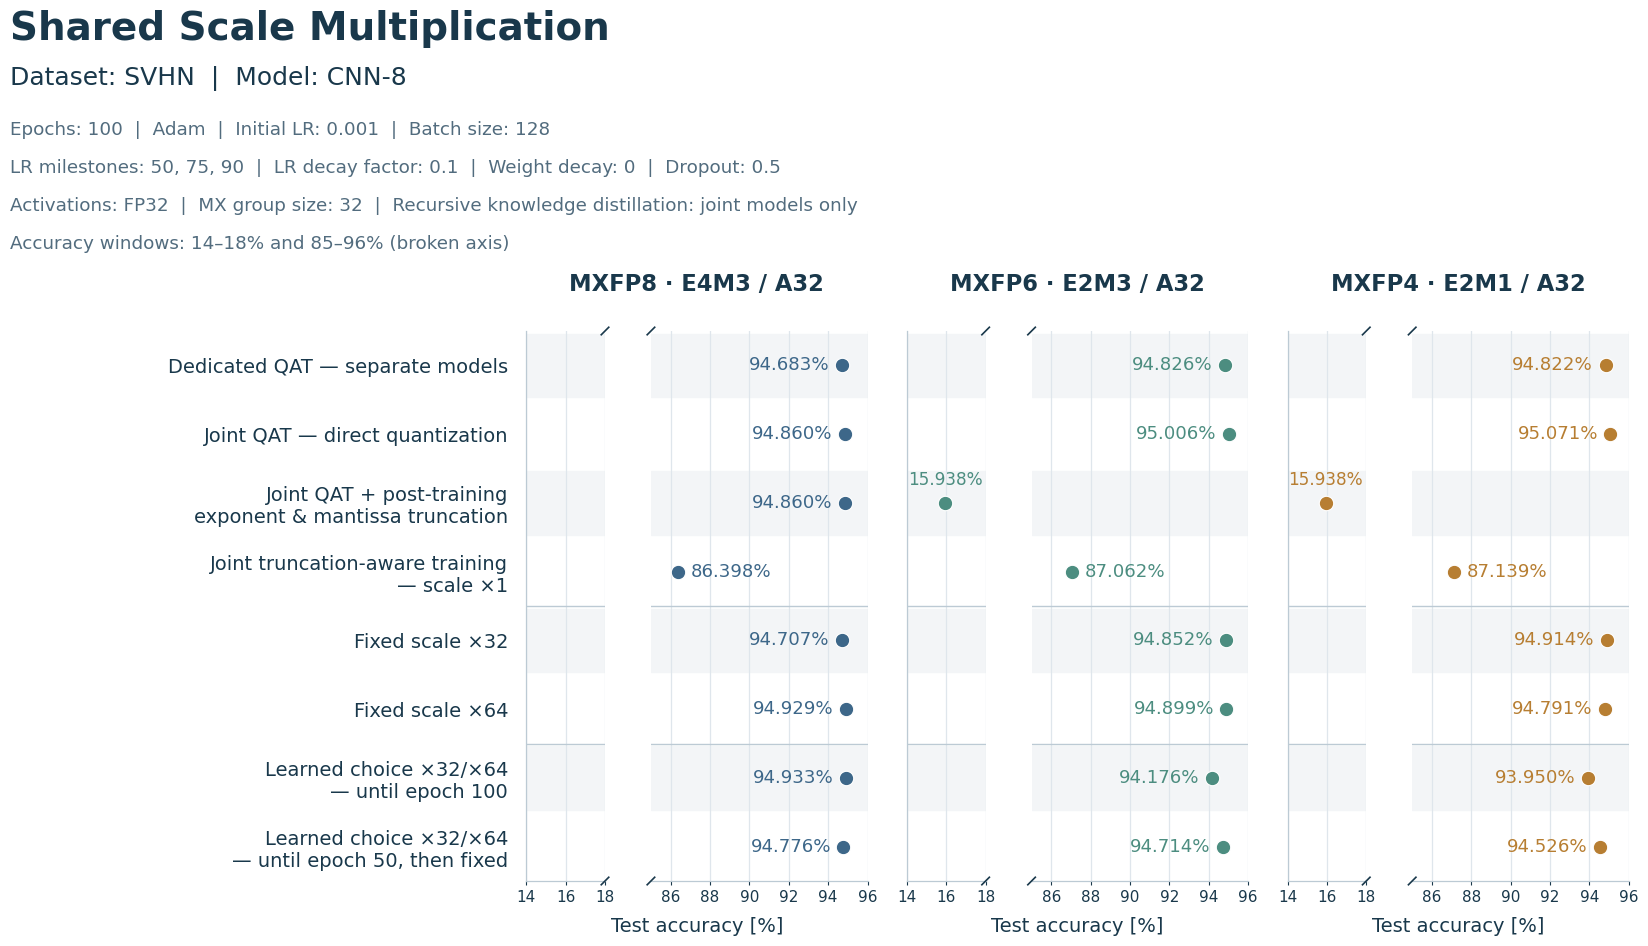

In [6]:
fig_shared_scale_accuracy = make_accuracy_figure(
    FIGURE_SELECTIONS['shared_scale_accuracy'], 'Shared Scale Multiplication')
plt.show()


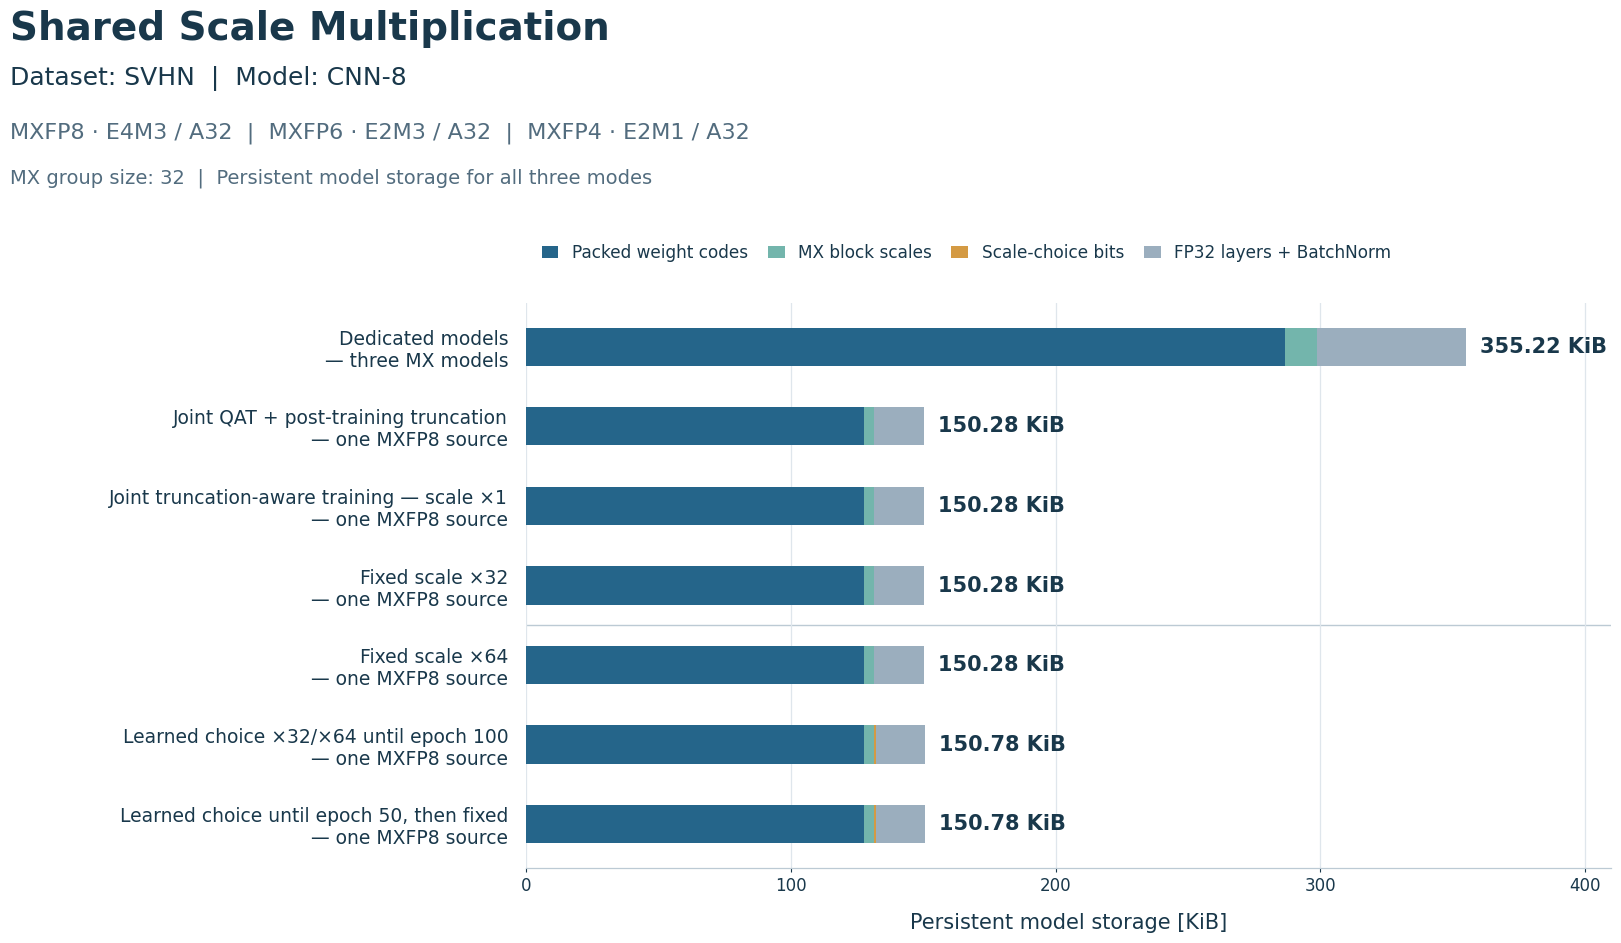

In [7]:
fig_shared_scale_storage = make_storage_figure(
    FIGURE_SELECTIONS['shared_scale_storage'], 'Shared Scale Multiplication')
plt.show()


## 3. Group size sensitivity

The original first four rows are repeated in each figure. The comparison below them uses **group sizes 16, 32 and 64 with the same fixed ×64 scale relationship**. The group-32 point and storage bar reuse `fixed_scale64`; they are not new measurements.

The storage plot retains fixed scale ×32 among its four original reference cases. The separate group-32 ×64 row provides the matching control for the group-size experiment. Each group-size figure has seven rows.


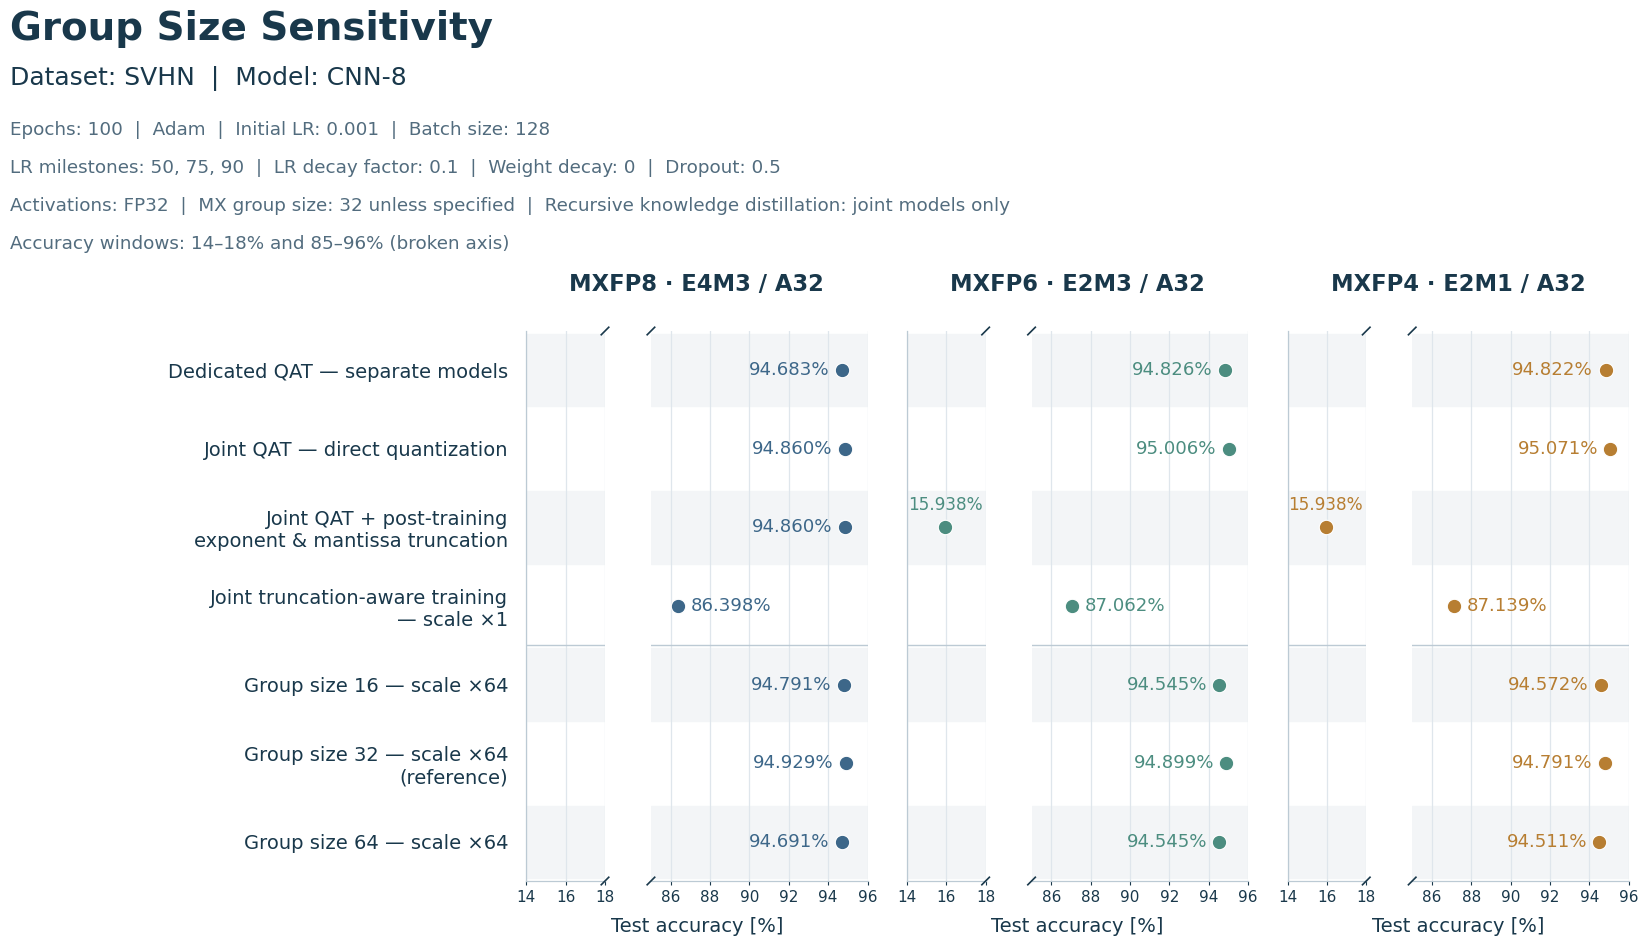

In [8]:
fig_group_size_accuracy = make_accuracy_figure(
    FIGURE_SELECTIONS['group_size_accuracy'], 'Group Size Sensitivity', group_study=True)
plt.show()


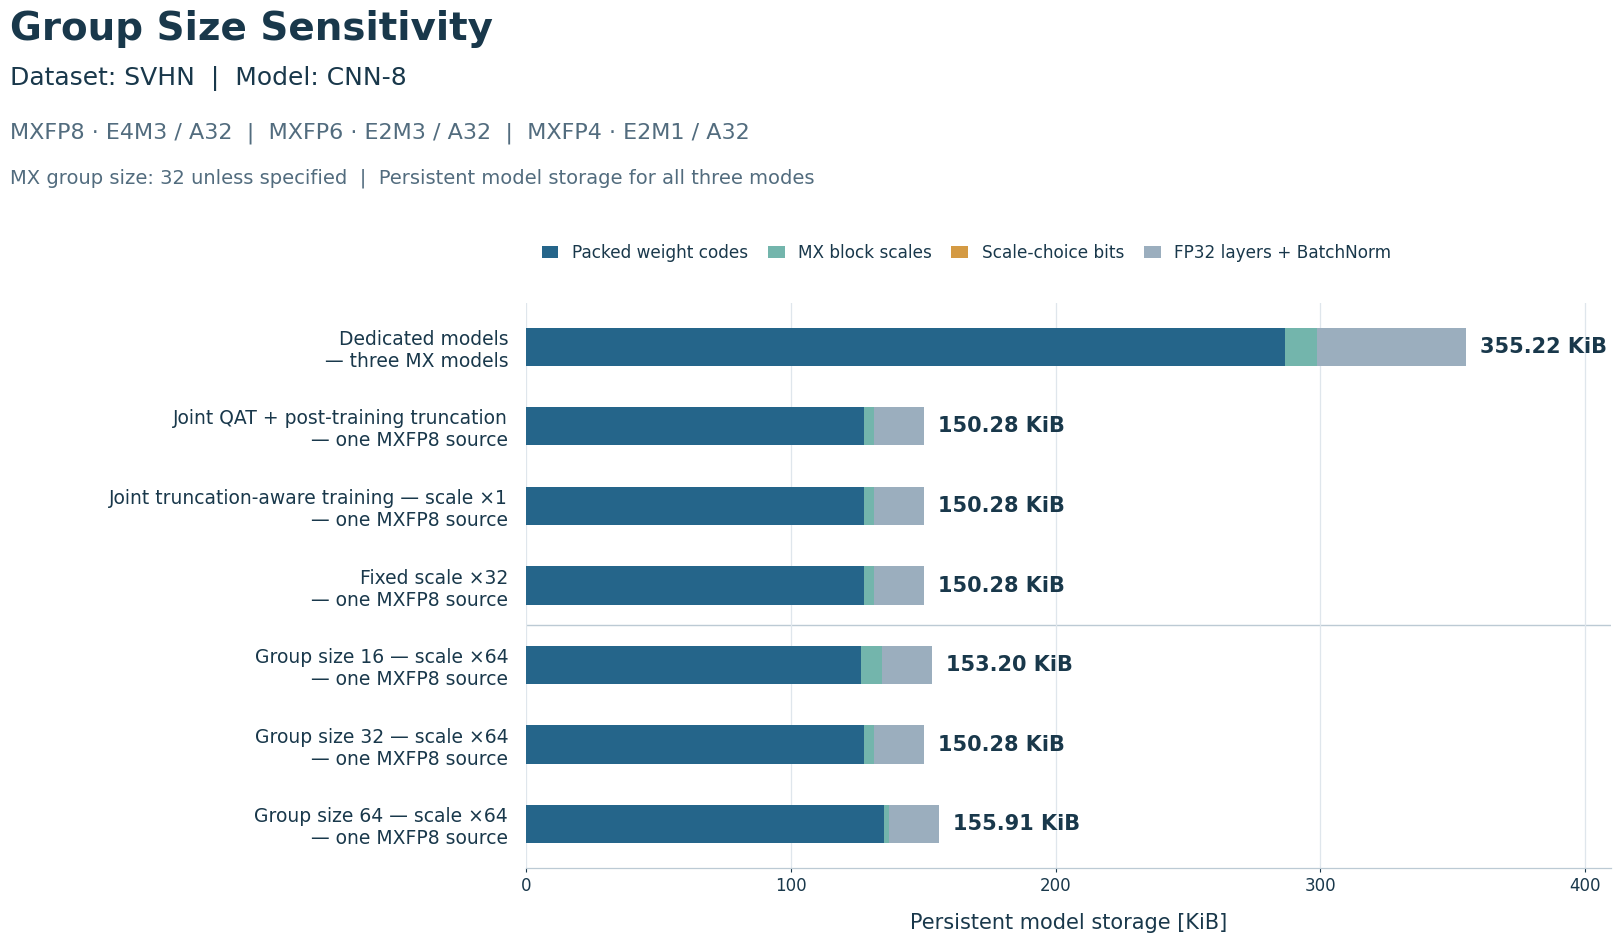

In [9]:
fig_group_size_storage = make_storage_figure(
    FIGURE_SELECTIONS['group_size_storage'], 'Group Size Sensitivity', group_study=True)
plt.show()


## 4. Storage metric and accuracy mapping

The direct joint-QAT accuracy row evaluates the three formats by direct quantization from the FP32 master weights. It has no separate single-MX-source bar in the original storage definition. The joint-QAT storage reference maps to **post-training truncation**, which uses one stored MXFP8 source and derives the lower formats from it. This mapping is preserved in both figure pairs.

Persistent storage includes packed weight codes, E8M0 block scales, per-block scale-choice bits where needed, and the retained FP32 layers and BatchNorm state. It excludes activations, gradients, optimizer state, decoded runtime copies, workspaces and container overhead. A32 activations still require runtime buffers during inference.

The learned-choice cases each require 510 bytes of choice bits. Those bits remain necessary after freezing the choices. Group sizes change both scale counts and row-tail padding; group 64 is therefore larger than group 32 in this specific tensor layout.


### Exact storage accounting

All cases use the same logical-payload accounting as the earlier figures. Container overhead, optimizer state, gradients, activations, decoded runtime copies and convolution workspaces are excluded. Auxiliary state is 19,248 bytes per model copy: 8,808 bytes for the FP32 first/last layers and 10,440 bytes for all five BatchNorm banks, including counters. Dedicated models have three independently trained auxiliary-state copies; each joint model has one.

At group size 32, the six MX layers contain 129,472 weights in 4,080 blocks, with 130,560 stored MXFP8 slots and 1,088 padding slots. The learned choice array uses 4,080 bits = 510 bytes. This changes 150.28125 KiB into 150.779296875 KiB for both learned-choice variants.

Group size changes both scale count and padding. Group 16 has 8,096 scales and 64 padding slots. Group 64 has only 2,160 scales but 8,768 padding slots. Consequently, the current group-64 layout is larger overall than group 32 despite having fewer scale entries. These are properties of this model's tensor shapes and row-wise layout, not a universal claim about larger groups.

The storage chart uses a zero-based continuous axis; the exact total labels make small differences visible. The narrow learned-choice segment is intentional and uses its true byte count.


### Status of the 8×8 experiment

A five-epoch 8×8 pilot was discussed previously, but the verified source dataset used here contains no 8×8 result at epoch 100. It is therefore not plotted as an equivalent completed 100-epoch run, and no storage value is inferred from the ordinary group-64 row.

An 8×8 grouping is two-dimensional; although it also has 64 values per group, its scale sharing and padding can differ from the one-dimensional group-64 experiment. Its final-checkpoint accuracy and layout report can be added as a separate row when available. No placeholder accuracy, copied group-64 result or zero-size storage bar is used.


## 5. Export

Run the following cell to export all four figures as **300 dpi PNG** and **vector SVG**. The four CSV tables retain the original unrounded percentages and integer byte counts. `figure_data.json` contains the complete unchanged source dataset; `figure_selections.json` records the rows shown in each figure.

Only named presentation outputs in `figures/` are updated. Original training logs, checkpoints and research data are not accessed or overwritten.


In [10]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = {
    'shared_scale_accuracy': fig_shared_scale_accuracy,
    'shared_scale_storage': fig_shared_scale_storage,
    'group_size_accuracy': fig_group_size_accuracy,
    'group_size_storage': fig_group_size_storage,
}
for name, figure in FIGURES.items():
    for extension in ('png', 'svg'):
        target = EXPORT_DIR / f'{name}.{extension}'
        figure.savefig(target, format=extension, dpi=EXPORT_DPI, facecolor='white')
        print(f'Saved: {target.as_posix()}')
    methods = FIGURE_SELECTIONS[name]
    if name.endswith('accuracy'):
        rows = [
            {'method_id': mid, 'method': ACCURACY_BY_ID[mid]['label'],
             'group_size': ACCURACY_BY_ID[mid]['group_size'], 'format': mode,
             'accuracy_percent': ACCURACY_BY_ID[mid]['values'][mode]['accuracy_percent'],
             'correct': ACCURACY_BY_ID[mid]['values'][mode]['correct'],
             'n': ACCURACY_BY_ID[mid]['values'][mode]['n']}
            for mid in methods for mode in DATA['formats']
        ]
    else:
        rows = [STORAGE_BY_METHOD[mid] for mid in methods]
    with (EXPORT_DIR / f'{name}.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
(EXPORT_DIR / 'figure_data.json').write_text(json.dumps(DATA, indent=2) + '\n', encoding='utf-8')
(EXPORT_DIR / 'figure_selections.json').write_text(
    json.dumps({'revision': REVISION, 'selections': FIGURE_SELECTIONS}, indent=2) + '\n', encoding='utf-8')
print('Saved: four CSV tables, figure_data.json and figure_selections.json')


Saved: figures/shared_scale_accuracy.png
Saved: figures/shared_scale_accuracy.svg
Saved: figures/shared_scale_storage.png
Saved: figures/shared_scale_storage.svg
Saved: figures/group_size_accuracy.png
Saved: figures/group_size_accuracy.svg
Saved: figures/group_size_storage.png
Saved: figures/group_size_storage.svg
Saved: four CSV tables, figure_data.json and figure_selections.json


## 6. Provenance

The primary measurements are the audited embedded records from `MX_onderzoeksoverzicht_meeting_20261029.ipynb`. The four references were read as literal JSON from the executed exponent-truncation notebook. The six added training IDs are `triple_scale32`, `triple_scale64`, `triple_learned100`, `triple_freeze50`, `triple_group16` and `triple_group64`.

All source member names, training configurations, checkpoint hashes, original metric hashes, lineage records and post-training evaluation identifiers are embedded in `DATA`. The freeze-at-50 branch's shared history and continued dynamic source scales are preserved. Storage layouts and scale-choice bits come from the same audited cost dataset.

The middle reference storage case is grounded in the recorded joint-direct MXFP8 export and the measured post-training conversion route. No native direct-quantization accuracy is relabelled as source-truncation accuracy. There is no claim that the current notebook newly validates a source-only runtime or reproduces a historical checkpoint bit for bit.

No original training metric was changed. Building this notebook executes plotting, data-integrity checks and exports only; it does not load binary models, rerun inference or train a model.


### This presentation revision

The source notebook was retrieved as `MX_Truncation_Research_SVHN_CNN8_Midterm.ipynb`.
Its SHA-256 before this revision is `4cf70c2d05bf369a7866a7ba00b064e9b68a3fda334fcb29bdb2998395f343dd`.
The `DATA` object was copied without changing any measurement or accounting entry.
The revision changes row selections, display labels for the existing group-32 control,
figure titles and spacing. It does not add an 8×8 result or a new storage scenario.
